# P15. Dynamic Liquid Stability and Re-orthonormalization

A dynamic liquid layer keeps the liquid's inertia (see P12). Solving one is a question of stability as much as accuracy. The shooting method carries each layer's independent solutions from its base to its top and combines them at the surface to meet the boundary conditions. In an unstably stratified liquid those solutions grow at different exponential rates, all turn toward the fastest growing one, and become nearly dependent. The surface combination then cancels large, nearly equal numbers, and the Love numbers lose digits down to a roundoff floor that no integration tolerance can lower. TidalPy prevents this by re-orthonormalizing the solutions as they integrate.

This notebook uses Europa with an iron core, a rocky mantle, a 115 km ocean, and a 25 km ice shell (the bundled `europa_dynamic`), and a copy whose ocean has a constant density. It:

1. Solves both worlds' $k_2$ from half an hour to $10^4$ days.
2. Compares four integration tolerances for accuracy, cost, and the stability of the surface solve.
3. Explains re-orthonormalization and shows the surface solve with and without it.
4. Shows how to set it and read what it did.
5. Measures its drawbacks.

In [1]:
%matplotlib inline
import copy
import math
import timeit

import numpy as np
import matplotlib.pyplot as plt

import TidalPy
from TidalPy.Structures import build_world

DAY = 86400.0
EPSILON = np.finfo(float).eps
EUROPA_PERIOD = 3.551181  # [days]
REFERENCE = dict(rtol=1.0e-12, atol=1.0e-14)
# (rtol, atol) pairs, loosest first. The default is 3e-8 for both.
TOLERANCES = ((1.0e-4, 1.0e-6), (1.0e-6, 1.0e-8), (3.0e-8, 3.0e-8), (1.0e-10, 1.0e-12))


def europa(constant_density_ocean=False):
    "The solved europa_dynamic, or a copy whose ocean has a constant density (an unstably stratified ocean)."
    world = build_world("europa_dynamic")
    if constant_density_ocean:
        config = copy.deepcopy(world.get_config_dict())
        config["layers"]["ocean"]["material"]["liquid"]["eos"] = {
            "model": "constant", "reference_density_kg_m3": 1050.0, "bulk_modulus_pa": 2.2e9}
        world = build_world(config)
    world.solve_eos(raise_on_fail=True)
    return world


def sweep(world, periods, **kwargs):
    """One degree-2 solve per forcing period [days]. Returns k2 and the surface solve's error amplification (NaN where
    a solve fails) and, for each solve, the ocean's integration steps and re-orthonormalizations and the surface solve's
    reciprocal condition number."""
    ocean = [zone["layer"] for zone in world.zones].index("ocean")
    result = {"k": np.full(len(periods), np.nan, dtype=complex)}
    for key in ("steps", "restarts", "amplification", "rcond"):
        result[key] = np.full(len(periods), np.nan)
    for i, period in enumerate(periods):
        world.solve_love_numbers(2.0 * math.pi / (period * DAY), 2, warnings=False, **kwargs)
        solution = world.release_radial_solution()
        result["steps"][i] = np.max(solution.steps_taken[ocean])
        result["restarts"][i] = solution.orthonormalizations[ocean]
        result["rcond"][i] = solution.surface_solve_rcond
        if solution.success:
            result["k"][i] = complex(solution.k)
            result["amplification"][i] = solution.surface_solve_amplification
    return result


def relative_error(k, reference):
    return np.abs(k - reference) / np.abs(reference)


def set_independence(value):
    "Set [numerical] minimum_solution_independence for this session; it applies to worlds already built too."
    TidalPy.reinit(provided_config={"numerical": {"minimum_solution_independence": value}})


neutral, constant = europa(), europa(constant_density_ocean=True)
for name, world in (("europa_dynamic", neutral), ("constant-density ocean", constant)):
    ocean = world["ocean"]
    rho = world.get_density(np.array([ocean.radius_inner + 1.0, ocean.radius_outer - 1.0]))
    k2 = complex(sweep(world, [EUROPA_PERIOD])["k"][0])
    print(f"{name:23s} ocean {ocean.radius_inner / 1e3:.0f} to {ocean.radius_outer / 1e3:.0f} km, density "
          f"{rho[0]:.0f} to {rho[1]:.0f} kg/m3; k2 at the orbital period {k2.real:.4f} {k2.imag:+.2e}j")

europa_dynamic          ocean 1421 to 1536 km, density 1082 to 1015 kg/m3; k2 at the orbital period 0.2630 -2.37e-03j
constant-density ocean  ocean 1421 to 1536 km, density 1050 to 1050 kg/m3; k2 at the orbital period 0.2595 -2.35e-03j


The bundled ocean's density follows its bulk modulus, from 1082 kg m$^{-3}$ at its base to 1015 at its top, so it is neutrally stratified (its buoyancy frequency $N^2$ is zero; see P12). The copy holds the ocean at 1050 kg m$^{-3}$ with a bulk modulus of 2.2 GPa. Its $N^2 = -\rho g^2 / K$ is negative, so it is unstably stratified, the hard case for a dynamic solve. At Europa's 3.55-day orbital period, the period of a synchronous moon's eccentricity tide, the two give $k_2$ of 0.2630 and 0.2595.

## $k_2$ Across the Forcing Period

The cell below solves both worlds at 400 forcing periods with the default tolerances, with the ocean dynamic (solid) and static (dashed). A static ocean drops the liquid's inertia and treats it as hydrostatic. The dotted line marks Europa's orbital period.

europa_dynamic          largest |k2| 28.5 at 3.13 hours; k2 at 1e4 days 0.2758
                        static vs dynamic: 1.6e-02 at 1 day, 1.3e-03 at the orbit, 1.7e-10 at 1e4 days; static k2 0.2626 at the orbit


constant-density ocean  largest |k2| 19.3 at 3.13 hours; k2 at 1e4 days 0.2711
                        static vs dynamic: 2.7e-02 at 1 day, 6.0e-03 at the orbit, 1.8e-06 at 1e4 days; static k2 0.2580 at the orbit
k2 difference between the oceans from the orbital period on: 1.3% to 1.7%


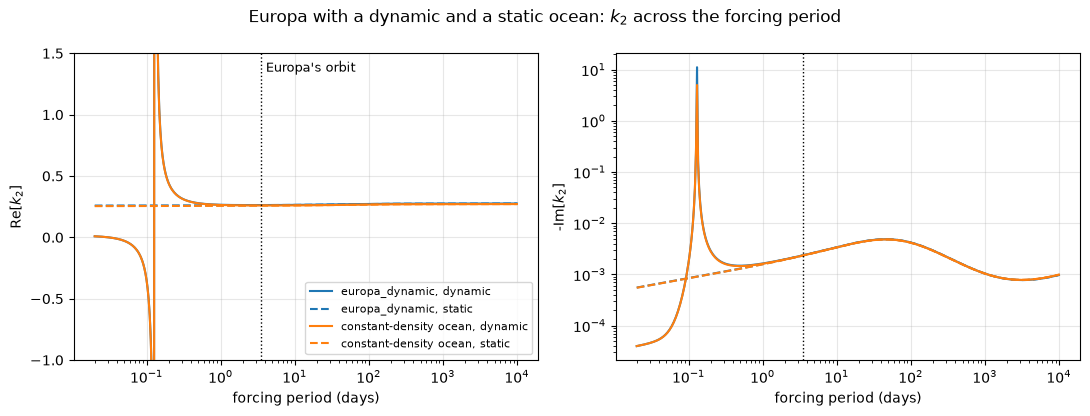

In [2]:
periods = np.logspace(np.log10(0.02), 4.0, 400)
frequencies = 2.0 * math.pi / (periods * DAY)
fig, (ax_re, ax_im) = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
k2_by_ocean = []
for name, world, color in (("europa_dynamic", neutral, "tab:blue"), ("constant-density ocean", constant, "tab:orange")):
    k2 = world.calc_love_numbers(frequencies, degree_l=2, warnings=False)["k"]
    # The same world with its ocean static (no inertia), then set back to dynamic for the rest of the notebook.
    world["ocean"].is_static = True
    k2_static = world.calc_love_numbers(frequencies, degree_l=2, warnings=False)["k"]
    world["ocean"].is_static = False
    k2_by_ocean.append(k2)
    for values, style, form in ((k2, "-", "dynamic"), (k2_static, "--", "static")):
        ax_re.plot(periods, values.real, style, color=color, label=f"{name}, {form}")
        ax_im.plot(periods, -values.imag, style, color=color, label=f"{name}, {form}")
    peak = np.argmax(np.abs(k2))
    print(f"{name:23s} largest |k2| {np.abs(k2[peak]):.1f} at {periods[peak] * 24:.2f} hours; k2 at 1e4 days "
          f"{k2[-1].real:.4f}")
    gap = relative_error(k2_static, k2)
    at = {label: np.argmin(np.abs(periods - p)) for label, p in (("1 day", 1.0), ("the orbit", EUROPA_PERIOD),
                                                                 ("1e4 days", 1.0e4))}
    print(f"{'':23s} static vs dynamic: " + ", ".join(f"{gap[i]:.1e} at {label}" for label, i in at.items())
          + f"; static k2 {k2_static[at['the orbit']].real:.4f} at the orbit")
past_orbit = periods >= EUROPA_PERIOD
difference = relative_error(k2_by_ocean[1], k2_by_ocean[0])[past_orbit]
print(f"k2 difference between the oceans from the orbital period on: {difference.min():.1%} to {difference.max():.1%}")
for ax in (ax_re, ax_im):
    ax.axvline(EUROPA_PERIOD, color="k", ls=":", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("forcing period (days)")
    ax.grid(True, alpha=0.3)
ax_re.set_ylim(-1.0, 1.5)
ax_re.set_ylabel("Re[$k_2$]")
ax_im.set_yscale("log")
ax_im.set_ylabel("-Im[$k_2$]")
ax_re.text(EUROPA_PERIOD * 1.15, 1.35, "Europa's orbit", fontsize=9)
ax_re.legend(loc="lower right", fontsize=8)
fig.suptitle("Europa with a dynamic and a static ocean: $k_2$ across the forcing period")
plt.tight_layout()
plt.show()

Both oceans resonate at 3.13 hours, the ocean's fundamental degree-2 gravity mode, where $|k_2|$ reaches 19 to 29 on this grid (the height depends on how near a sample falls to the resonance). At periods just shorter than the mode $\mathrm{Re}[k_2]$ is negative. Longer than it, $k_2$ settles to the body's tidal response, and from a day to $10^4$ days $\mathrm{Re}[k_2]$ stays between 0.26 and 0.28 while $-\mathrm{Im}[k_2]$ follows the mantle's and shell's viscoelastic response, peaking near 45 days. From the orbital period on, the two oceans' $k_2$ differ by 1.3 to 1.7 percent, from their different densities and stratification.

A static ocean has no inertia, so it has no mode. Its $k_2$ stays near 0.26 down to half an hour, where the dynamic ocean's has resonated and changed sign. The two forms differ by 1.6 percent (bundled ocean) and 2.7 percent (constant density) at 1 day, and by 0.13 and 0.6 percent at the orbital period, where the static $k_2$ are 0.2626 and 0.2580. At $10^4$ days they differ by $2 \times 10^{-10}$ and $2 \times 10^{-6}$. The static form is the long-period limit of a neutral dynamic liquid, and the unstably stratified ocean approaches it more slowly.

## Accuracy, Cost, and Stability Across Tolerances

Each solve below is compared with an `rtol = 1e-12`, `atol = 1e-14` solve of the same world, at 31 periods and four `(rtol, atol)` pairs. The top right panel counts the integration steps through the ocean, which the ocean's solutions share. The bottom panels give the two measures of the surface solve's stability that the next section explains, the error amplification and the reciprocal condition number.

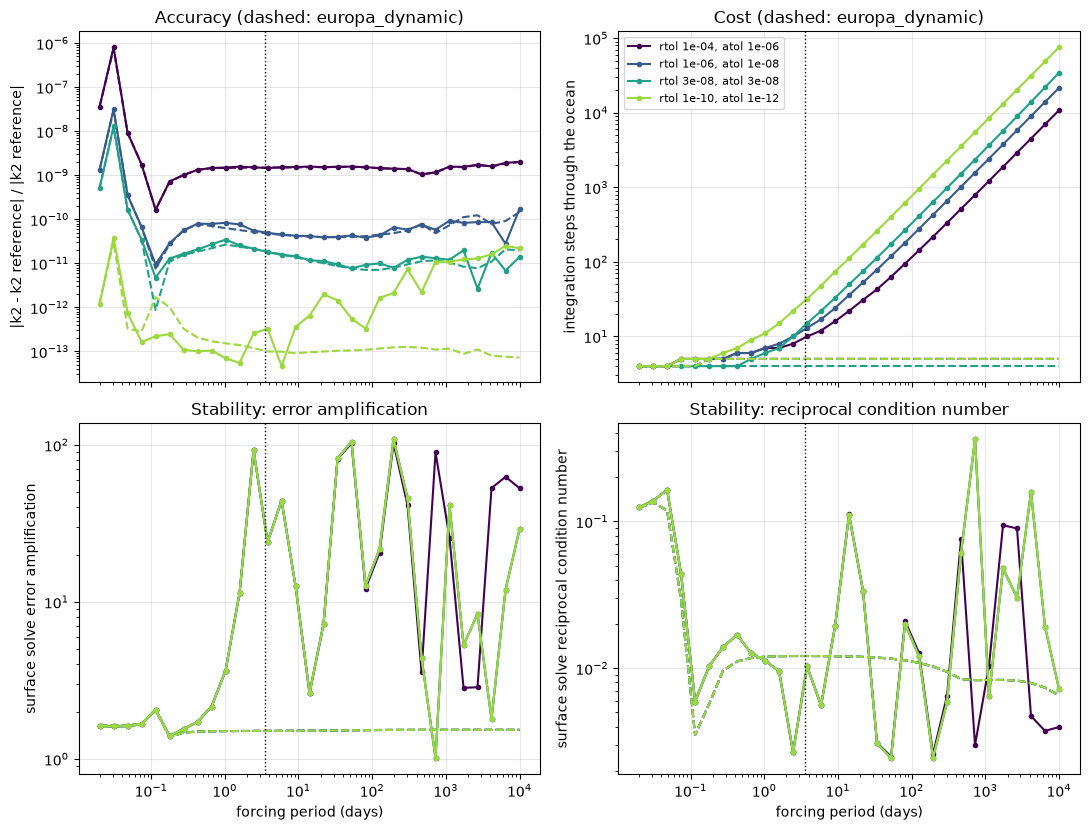

      rtol, atol     ocean  worst error  steps at 1e4 days
  1e-04,   1e-06   neutral      7.6e-07                  5
  1e-04,   1e-06  constant      8.0e-07              10807
  1e-06,   1e-08   neutral      3.0e-08                  5
  1e-06,   1e-08  constant      3.2e-08              21608
  3e-08,   3e-08   neutral      1.2e-08                  4
  3e-08,   3e-08  constant      1.3e-08              34500
  1e-10,   1e-12   neutral      3.1e-11                  5
  1e-10,   1e-12  constant      3.8e-11              75610
neutral ocean over every tolerance: amplification 1.4 to 2, rcond 4e-03 to 1e-01
constant ocean over every tolerance: amplification 1.0 to 109, rcond 2e-03 to 4e-01
constant ocean at     100 days: the reference differs from an rtol 1e-13 solve by 2e-12
constant ocean at    1000 days: the reference differs from an rtol 1e-13 solve by 5e-12


constant ocean at   10000 days: the reference differs from an rtol 1e-13 solve by 4e-11


In [3]:
periods = np.logspace(np.log10(0.02), 4.0, 31)
reference = {"neutral": sweep(neutral, periods, **REFERENCE), "constant": sweep(constant, periods, **REFERENCE)}
runs = {(name, tol): sweep(world, periods, rtol=tol[0], atol=tol[1])
        for name, world in (("neutral", neutral), ("constant", constant)) for tol in TOLERANCES}

fig, ((ax_err, ax_steps), (ax_amp, ax_rcond)) = plt.subplots(2, 2, figsize=(11, 8.4), sharex=True)
for color, tol in zip(plt.cm.viridis(np.linspace(0.0, 0.85, len(TOLERANCES))), TOLERANCES):
    label = f"rtol {tol[0]:.0e}, atol {tol[1]:.0e}"
    for name, style in (("constant", "o-"), ("neutral", "--")):
        run = runs[(name, tol)]
        label_once = label if name == "constant" else None
        ax_err.loglog(periods, relative_error(run["k"], reference[name]["k"]), style, color=color, ms=3,
                      label=label_once)
        ax_steps.loglog(periods, run["steps"], style, color=color, ms=3, label=label_once)
        ax_amp.loglog(periods, run["amplification"], style, color=color, ms=3, label=label_once)
        ax_rcond.loglog(periods, run["rcond"], style, color=color, ms=3, label=label_once)
for ax in (ax_err, ax_steps, ax_amp, ax_rcond):
    ax.axvline(EUROPA_PERIOD, color="k", ls=":", lw=1)
    ax.grid(True, alpha=0.3)
for ax in (ax_amp, ax_rcond):
    ax.set_xlabel("forcing period (days)")
ax_err.set_ylabel("|k2 - k2 reference| / |k2 reference|")
ax_err.set_title("Accuracy (dashed: europa_dynamic)")
ax_steps.set_ylabel("integration steps through the ocean")
ax_steps.set_title("Cost (dashed: europa_dynamic)")
ax_amp.set_ylabel("surface solve error amplification")
ax_amp.set_title("Stability: error amplification")
ax_rcond.set_ylabel("surface solve reciprocal condition number")
ax_rcond.set_title("Stability: reciprocal condition number")
ax_steps.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'rtol, atol':>16s} {'ocean':>9s} {'worst error':>12s} {'steps at 1e4 days':>18s}")
for tol in TOLERANCES:
    for name in ("neutral", "constant"):
        run = runs[(name, tol)]
        error = relative_error(run["k"], reference[name]["k"])
        print(f"{tol[0]:7.0e}, {tol[1]:7.0e} {name:>9s} {np.nanmax(error):12.1e} {int(run['steps'][-1]):18d}")
for name in ("neutral", "constant"):
    amplification = np.concatenate([runs[(name, tol)]["amplification"] for tol in TOLERANCES])
    rcond = np.concatenate([runs[(name, tol)]["rcond"] for tol in TOLERANCES])
    print(f"{name} ocean over every tolerance: amplification {np.nanmin(amplification):.1f} to "
          f"{np.nanmax(amplification):.0f}, rcond {np.nanmin(rcond):.0e} to {np.nanmax(rcond):.0e}")
# How good is the reference? Its difference from an rtol = 1e-13 solve.
for period in (100.0, 1000.0, 1.0e4):
    k_reference = sweep(constant, [period], **REFERENCE)["k"][0]
    k_tighter = sweep(constant, [period], rtol=1.0e-13, atol=1.0e-15)["k"][0]
    print(f"constant ocean at {period:7.0f} days: the reference differs from an rtol 1e-13 solve by "
          f"{relative_error(k_reference, k_tighter):.0e}")

The $k_2$ error follows the tolerance at every period for both oceans. Its worst values, from the loosest tolerance to the tightest, are $8 \times 10^{-7}$, $3 \times 10^{-8}$, $10^{-8}$, and $4 \times 10^{-11}$. They come at 45 minutes, where $\mathrm{Re}[k_2]$ passes through zero and a relative error is largest. Beyond a few hundred days the constant-density ocean's two tightest tolerances meet near $10^{-11}$. The reference is no better there, since it differs from an `rtol = 1e-13` solve by $2 \times 10^{-12}$ at 100 days, $5 \times 10^{-12}$ at 1000 days, and $4 \times 10^{-11}$ at $10^4$ days. At long periods an unstably stratified ocean's accuracy has a floor that grows with the period, as roundoff accumulates over its thousands of steps.

The cost is where the oceans differ. The bundled ocean takes 4 or 5 steps at every period. The constant-density ocean's steps grow in proportion to the period beyond a few days, to 10807 at $10^4$ days for the loosest tolerance and 75610 for the tightest, because the integrator follows its solutions' exponential growth.

The surface solve stays stable throughout. The bundled ocean's error amplification is 1.4 to 2 at every period and tolerance. The constant-density ocean's jumps between 1 and about 110, set by how far its solutions have drifted since their last re-orthonormalization when they reach the top of the ocean, and it does not grow with the period. Its reciprocal condition number stays at or above $2 \times 10^{-3}$. The next section shows the same ocean without re-orthonormalization.

## Re-orthonormalization

### Why the Solutions Lose Independence

A shooting solve carries three independent solutions through a solid layer and two through a dynamic liquid, each started at the layer's base. In an unstably stratified liquid they grow through the layer as $e^E$, with $E$ proportional to the forcing period (P12 derives $E$). They grow at different rates, so each turns toward the fastest growing one, and by the top of the layer they are nearly parallel. The surface boundary conditions need a combination of them in which those large, nearly equal parts cancel. The near-dependence amplifies both the integration error and roundoff in that combination. A tighter tolerance reduces the integration error, but not below the roundoff floor.

Every solution carries two measures of that loss.

- `surface_solve_amplification` is how much the surface solve amplifies a relative error in the solutions. The best relative accuracy a solve can reach is about this times machine epsilon, $2.2 \times 10^{-16}$. TidalPy logs a warning when that exceeds `rtol`, or when the amplification exceeds $10^8$.
- `surface_solve_rcond` is the reciprocal condition number of the surface system. The solution's constants carry the integration error divided by roughly this number. TidalPy logs a warning when it is below `rtol` and fails the solve below `[numerical] minimum_surface_rcond` ($10^{-12}$).

### What It Does

Re-orthonormalization (Godunov 1961; Conte 1966) watches a layer's solutions as they integrate, through their normalized Gram determinant, 1 when they are orthogonal and 0 when they are dependent. Where the determinant has fallen by the factor `[numerical] minimum_solution_independence` (default $10^{-4}$), the integration stops, the solutions are replaced by an orthonormal basis of the same span (a QR factorization, $Y = QR$), and a new integration continues from it. Nothing is approximated, since the equations are linear. The solutions before a restart equal the new ones times $R$ at every radius, and the constants the surface solve finds are carried back down through each $R$. The solutions keep their span and lose their near-dependence. The determinant and the new basis are taken with each radial function scaled to its characteristic size, so a solve in SI units restarts where a non-dimensional one does.

The cell below solves the constant-density ocean with re-orthonormalization switched off (`minimum_solution_independence = 0`) at three tolerances, and with it on at the default tolerance, against the reference.

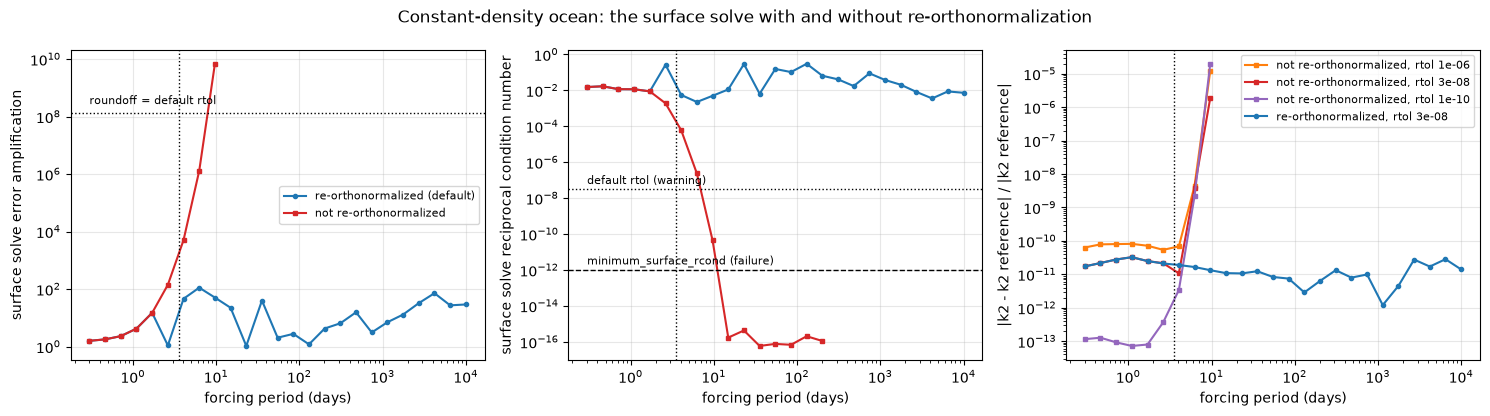

not re-orthonormalized: rcond below the default rtol from 9.7 days and below minimum_surface_rcond from 14.9 days
not re-orthonormalized: every solve fails from 15 days
at   2.6 days: amplification 1.4e+02 without and 1.1e+00 with re-orthonormalization; errors without, by rtol: 5e-11, 2e-11, 4e-13
at   9.7 days: amplification 6.8e+09 without and 5.0e+01 with re-orthonormalization; errors without, by rtol: 1e-05, 2e-06, 2e-05
re-orthonormalized: amplification at most 111, rcond at least 2e-03, 5399 restarts in the ocean at 1e4 days


In [4]:
periods = np.logspace(np.log10(0.3), 4.0, 25)
truth = sweep(constant, periods, **REFERENCE)["k"]
on = sweep(constant, periods)
set_independence(0.0)   # re-orthonormalization off
try:
    off = {tol: sweep(constant, periods, rtol=tol[0], atol=tol[1]) for tol in TOLERANCES[1:]}
finally:
    TidalPy.reinit(provided_config="default")   # back to the configured settings (re-orthonormalization on)

fig, (ax_amp, ax_rcond, ax_err) = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
ax_amp.loglog(periods, on["amplification"], "o-", ms=3, color="tab:blue", label="re-orthonormalized (default)")
ax_amp.loglog(periods, off[TOLERANCES[2]]["amplification"], "s-", ms=3, color="tab:red",
              label="not re-orthonormalized")
ax_amp.axhline(3.0e-8 / EPSILON, color="k", ls=":", lw=1)
ax_amp.text(periods[0], 3.0e-8 / EPSILON * 2.0, "roundoff = default rtol", fontsize=8)
ax_amp.set_ylabel("surface solve error amplification")
ax_rcond.loglog(periods, on["rcond"], "o-", ms=3, color="tab:blue")
ax_rcond.loglog(periods, off[TOLERANCES[2]]["rcond"], "s-", ms=3, color="tab:red")
ax_rcond.axhline(3.0e-8, color="k", ls=":", lw=1)
ax_rcond.text(periods[0], 3.0e-8 * 2.0, "default rtol (warning)", fontsize=8)
ax_rcond.axhline(1.0e-12, color="k", ls="--", lw=1)
ax_rcond.text(periods[0], 1.0e-12 * 2.0, "minimum_surface_rcond (failure)", fontsize=8)
ax_rcond.set_ylabel("surface solve reciprocal condition number")
for color, tol in zip(("tab:orange", "tab:red", "tab:purple"), TOLERANCES[1:]):
    ax_err.loglog(periods, relative_error(off[tol]["k"], truth), "s-", ms=3, color=color,
                  label=f"not re-orthonormalized, rtol {tol[0]:.0e}")
ax_err.loglog(periods, relative_error(on["k"], truth), "o-", ms=3, color="tab:blue",
              label="re-orthonormalized, rtol 3e-08")
ax_err.set_ylabel("|k2 - k2 reference| / |k2 reference|")
for ax in (ax_amp, ax_rcond, ax_err):
    ax.axvline(EUROPA_PERIOD, color="k", ls=":", lw=1)
    ax.set_xlabel("forcing period (days)")
    ax.grid(True, alpha=0.3)
ax_amp.legend(fontsize=8, loc="center right")
ax_err.legend(fontsize=8)
fig.suptitle("Constant-density ocean: the surface solve with and without re-orthonormalization")
plt.tight_layout()
plt.show()

failed = periods[np.isnan(off[TOLERANCES[2]]["k"])]
rcond_off = off[TOLERANCES[2]]["rcond"]
print(f"not re-orthonormalized: rcond below the default rtol from {periods[rcond_off < 3e-8][0]:.1f} days and below "
      f"minimum_surface_rcond from {periods[rcond_off < 1e-12][0]:.1f} days")
print(f"not re-orthonormalized: every solve fails from {failed[0]:.0f} days" if failed.size else "no failures")
for period in (3.0, 10.0):
    i = np.argmin(np.abs(periods - period))
    print(f"at {periods[i]:5.1f} days: amplification {off[TOLERANCES[2]]['amplification'][i]:.1e} without and "
          f"{on['amplification'][i]:.1e} with re-orthonormalization; errors without, by rtol: "
          + ", ".join(f"{relative_error(off[tol]['k'][i], truth[i]):.0e}" for tol in TOLERANCES[1:]))
print(f"re-orthonormalized: amplification at most {np.nanmax(on['amplification']):.0f}, rcond at least "
      f"{np.nanmin(on['rcond']):.0e}, {int(on['restarts'][-1])} restarts in the ocean at 1e4 days")

Up to about 2 days the solves with and without re-orthonormalization agree, since the solutions have not yet lost much independence. Beyond that, without it, the amplification grows by about an order of magnitude per day of forcing period, from $1.4 \times 10^2$ at 2.6 days to $6.8 \times 10^9$ at 9.7 days. The reciprocal condition number is below the warning line by 9.7 days and below the failure line by 15 days. At 9.7 days $k_2$ is off by $10^{-5}$ and $2 \times 10^{-6}$ at the two looser tolerances and still by $2 \times 10^{-5}$ at `rtol = 1e-10`, near the roundoff floor. From 15 days every solve fails, at first in the surface solve, and past about 200 days in the integration itself, as the solutions outgrow what a step can resolve, so no condition number is recorded there. With re-orthonormalization the amplification stays at or below 111 and the reciprocal condition number at or above $2 \times 10^{-3}$ out to $10^4$ days, where the ocean restarts 5399 times, and the error stays between $10^{-12}$ and $3 \times 10^{-11}$.

## Using It

Re-orthonormalization is on by default. Its is set by `minimum_solution_independence` in the `[numerical]` table of the TidalPy configuration (set this to 0 to turn it off). Change it for every session in `TidalPy_Configs.toml` (see B01), or for this session with `TidalPy.reinit(provided_config={"numerical": {"minimum_solution_independence": value}})`, as `set_independence` above does. The change applies to worlds already built. `TidalPy.reinit(provided_config="default")` returns to the configured settings, dropping every other session override too, and the cells here call it in a `finally` block so an error cannot leave the setting changed.

A poorly conditioned solve logs a warning unless it is called with `warnings=False`, as every solve above is. The cell below solves the constant-density ocean at 9.7 days without re-orthonormalization and with warnings on.

In [5]:
set_independence(0.0)
try:
    constant.solve_love_numbers(2.0 * math.pi / (9.7 * DAY), 2)   # warnings on, as by default
finally:
    TidalPy.reinit(provided_config="default")

[TidalPy] [warning] Radial solver surface boundary condition solve is poorly conditioned (error amplification ~7.7e+09; achievable relative accuracy ~1.7e-06; reciprocal condition number 3.9e-11; requested integration rtol 3.0e-08). Love numbers and surface outputs may be much less accurate than requested. If [numerical] minimum_solution_independence is 0, set it above 0 to re-orthonormalize the solutions; otherwise compare a solve at a tighter rtol. Tightening tolerances cannot beat the roundoff floor.


The warning gives the amplification, the accuracy it allows, and the reciprocal condition number against the requested `rtol`, and names the setting to change. Each solution also counts its restarts per layer in `orthonormalizations`, beside `steps_taken`, and `print_diagnostics` reports both with the two surface measures, as below for the constant-density ocean at 1000 days with the default setting.

In [6]:
print("minimum_solution_independence =", TidalPy.config["numerical"]["minimum_solution_independence"])
constant.solve_love_numbers(2.0 * math.pi / (1000.0 * DAY), 2, warnings=False)
constant.release_radial_solution().print_diagnostics()

minimum_solution_independence = 0.0001

	Equation of State Solver:
		Success:           True
		Error code:        0
		Message:           Equation of state solver finished without issue.
		Iterations:        4
		Pressure Error:    2.149e+01 Pa
		Central Pressure:  4.787e+09 Pa
		Mass:              4.800e+22 kg
		MOI:               4.045e+34 kg m2 (factor 0.3458, sphere ratio 0.8645)
		Surface gravity:   1.315e+00 m s-2

	Radial Solver Results:
		Success:     True
		Error code:  0
		Message:     RadialSolver.ShootingMethod: Completed without any noted issues.
		Steps taken and re-orthonormalizations, per layer:
			Layer 0 = 28 steps, 0 re-orthonormalizations
			Layer 1 = 8 steps, 0 re-orthonormalizations
			Layer 2 = 3253 steps, 539 re-orthonormalizations
			Layer 3 = 4 steps, 0 re-orthonormalizations
		Surface solve amplification:  2.155e+01
		Surface solve rcond:          1.235e-02
		k_2 = (0.2703170908994754-0.0010382608336835927j)
		h_2 = (1.2621031015022135-0.003441540079984811j)
		

The ocean (layer 2) took 3253 steps and 539 restarts, one every 6 steps, while the core, mantle, and shell needed none. An amplification of 22 leaves roundoff of about $5 \times 10^{-15}$, far below the tolerance.

## Drawbacks

Re-orthonormalization fixes the conditioning but has costs of its own. The cell below repeats the 100-day and 1000-day solves of the constant-density ocean at six thresholds, with each solve's restarts, steps, $k_2$ error, and time.

In [7]:
periods = (100.0, 1000.0)
truth = sweep(constant, periods, **REFERENCE)["k"]
print(f"{'threshold':>9s}" + "".join(f" | {f'{p:g} days: restarts, steps, error, time':>40s}" for p in periods))
try:
    for threshold in (1.0e-10, 1.0e-6, 1.0e-4, 1.0e-2, 0.5, 0.9):
        set_independence(threshold)
        run = sweep(constant, periods)
        cells = []
        for i, period in enumerate(periods):
            frequency = 2.0 * math.pi / (period * DAY)
            seconds = min(timeit.repeat(lambda: constant.solve_love_numbers(frequency, 2, warnings=False),
                                        number=3, repeat=3)) / 3
            cells.append(f"{int(run['restarts'][i]):6d} {int(run['steps'][i]):6d} "
                         f"{relative_error(run['k'][i], truth[i]):9.0e} {seconds * 1e3:7.2f} ms")
        print(f"{threshold:9.0e}" + "".join(f" | {cell:>40s}" for cell in cells))
finally:
    TidalPy.reinit(provided_config="default")

threshold |   100 days: restarts, steps, error, time |  1000 days: restarts, steps, error, time


    1e-10 |           21    329     1e-09    1.25 ms |          217   3491     2e-09   10.20 ms


    1e-06 |           35    328     5e-12    1.26 ms |          361   3302     6e-12   10.17 ms


    1e-04 |           53    328     6e-12    1.20 ms |          539   3253     1e-11   10.66 ms


    1e-02 |          102    415     7e-12    1.63 ms |         1030   4128     2e-11   15.14 ms


    5e-01 |          350    705     8e-12    3.30 ms |         3490   6986     2e-11   35.69 ms


    9e-01 |          843   1690     8e-12    8.45 ms |         8342  16689     2e-11   89.78 ms


- **It does not remove the growth.** Up to the default threshold the steps barely change, about 330 at 100 days and 3250 to 3500 at 1000 days, because between restarts the integrator still follows the solutions' exponential growth. An unstably stratified liquid's steps grow in proportion to the period at any threshold. A neutral or a static liquid avoids that growth altogether (P12).
- **Each restart has a cost.** A restart locates the point where the determinant crossed the threshold, factors the solutions, sets up a new integration (which keeps the last accepted step size), and stores another segment of the solution. At thresholds of 0.5 and 0.9 the restarts come so often that the steps double and then quintuple, and a 1000-day solve takes roughly 3 and 7 to 9 times as long as at the default, with no gain in accuracy.
- **Too small a threshold lets accuracy go first.** At $10^{-10}$ the solutions' Gram determinant falls to $10^{-10}$ before each restart (for two solutions, an angle of about $10^{-5}$ radians between them), and the 1000-day error rises to $2 \times 10^{-9}$. Thresholds from $10^{-6}$ to $10^{-2}$ give the same $k_2$ here, and the default sits between them.
- **Each restart keeps a segment of the solution.** A solve stores its radial functions as continuous (dense) output so they can be evaluated at any radius afterward, one segment per restart. At very long periods the segments exceed `max_ram_MB` (500 MB by default) and the solve fails, as at $10^5$ days below. `love_only=True` keeps only what the Love numbers need, and raising `max_ram_MB` keeps the radial functions.

In [8]:
frequency = 2.0 * math.pi / (1.0e5 * DAY)
ocean = [zone["layer"] for zone in constant.zones].index("ocean")
for love_only in (False, True):
    seconds = timeit.timeit(lambda: constant.solve_love_numbers(frequency, 2, warnings=False, love_only=love_only),
                            number=1)
    solution = constant.release_radial_solution()
    outcome = f"k2 = {complex(solution.k):.5f}" if solution.success else solution.message.split(":: ")[-1].strip()
    print(f"love_only={love_only!s:5s}: {int(solution.orthonormalizations[ocean])} restarts in the ocean, "
          f"{seconds:.2f} s. {outcome}")

love_only=False: 35807 restarts in the ocean, 0.95 s. The dense solution kept through layer 2 (35808 re-orthonormalized segments in this layer) exceeds max_ram_MB. Raise max_ram_MB, or solve with love_only.


love_only=True : 53993 restarts in the ocean, 1.03 s. k2 = 0.27266-0.00370j


Without `love_only` the solve stops after 35807 restarts, when the stored segments pass `max_ram_MB`. With it all 53993 restarts run, in about a second.

## Summary

| | Re-orthonormalization off | On (default) |
|---|---|---|
| Surface amplification | Grows exponentially with the period | Stays between 1 and about 100 |
| $k_2$ accuracy | Lost to roundoff beyond a few days, at any tolerance; every solve fails beyond about 15 days here | Follows the tolerance, down to a floor near $10^{-11}$ at long periods |
| Steps | Grow with the period in an unstably stratified liquid | The same, plus a small cost per restart |

Keep the default for dynamic liquids. Judge a solve by `surface_solve_amplification` and `surface_solve_rcond`, or `print_diagnostics`, since the amplification times $2.2 \times 10^{-16}$ is the best relative accuracy it can reach at any tolerance. Tighten `rtol` and `atol` for more digits, at the cost of more steps. For very long periods in an unstably stratified liquid, solve with `love_only=True`, or use a neutral or static liquid, which avoids the growth.